# Week 4: Map your set

To start, save a copy to your Drive (File → Save a copy in Drive), then run the cells in order. It runs on Colab's free CPU runtime. The outputs below are from the 56 museum chairs in the week 4 slides.

## 1. Setup

This loads CLIP, which takes about a minute.

In [1]:
import csv, glob, io, os, shutil, sys, textwrap, zipfile
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install umap-learn pillow-heif sentence-transformers
import numpy as np, requests, torch, umap
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from PIL import Image, ImageOps
from transformers import CLIPModel, CLIPProcessor
try:
    from pillow_heif import register_heif_opener
    register_heif_opener()  # so that iPhone .heic photos open like any other image
except ImportError:
    pass

%config InlineBackend.figure_formats = ["jpeg"]  # smaller pictures in the saved notebook

dev = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(dev).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

def load_yours(folder, size=1024):
    """Copy your images into `folder` from DRIVE_FOLDER or an uploaded zip: turned upright, saved as .jpg, at most
    `size` pixels wide or tall. Returns any .csv files that came with them."""
    items = []
    if DRIVE_FOLDER:
        from google.colab import drive
        drive.mount("/content/drive")
        root = os.path.join("/content/drive", DRIVE_FOLDER)
        items = [(os.path.relpath(p, root), open(p, "rb").read())
                 for p in sorted(glob.glob(os.path.join(root, "**", "*"), recursive=True)) if os.path.isfile(p)]
    else:
        from google.colab import files
        print("Pick a zip of your images:")
        for name, data in files.upload().items():
            if name.lower().endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(data))
                items += [(n, z.read(n)) for n in z.namelist() if not n.endswith("/")]
            else:
                items.append((name, data))
    saved, skipped, csvs = 0, [], {}
    for name, data in items:
        base = os.path.basename(name)
        if "__MACOSX" in name or base.startswith("."):
            continue
        if base.lower().endswith(".csv"):
            csvs[base] = data
            continue
        try:
            im = ImageOps.exif_transpose(Image.open(io.BytesIO(data))).convert("RGB")
        except Exception:
            skipped.append(base)
            continue
        im.thumbnail((size, size))
        im.save(os.path.join(folder, os.path.splitext(base)[0] + ".jpg"), quality=92)
        saved += 1
    print(f"saved {saved} images")
    if skipped:
        print("Skipped, because they did not open as images:", ", ".join(skipped))
    return csvs

print("ready")

ready


## 2. Your images

With USE_EXAMPLE = True, it downloads the museum chairs. To use your own, set it to False, change SUBJECT to what your designs are (for example "lamp" or "poster"), and run the cell again. It will ask for a zip of your 20 to 40 designs. If they are in a folder in your Google Drive, you can put the folder in DRIVE_FOLDER instead, for example "MyDrive/my-set". Photos from an iPhone (.heic) work too, and the cell lists any file it could not open.

In [2]:
USE_EXAMPLE = True  # True: the 56 museum chairs. False: your own images.
DRIVE_FOLDER = ""   # with your own images: a folder in your Google Drive, for example "MyDrive/my-set". Empty: upload a zip.
SUBJECT = "chair"   # what your designs are, for the searches below, for example "lamp" or "poster"
TRAIN_DIR = "train"
base = "https://raw.githubusercontent.com/chuanenlin/mlfordesign/main/examples/museum-chairs/"

# Start from an empty folder, so the example's images and yours never end up in the same set.
marker = os.path.join(TRAIN_DIR, ".from")
if not (USE_EXAMPLE and os.path.exists(marker) and open(marker).read() == "example"):
    shutil.rmtree(TRAIN_DIR, ignore_errors=True)
os.makedirs(TRAIN_DIR, exist_ok=True)
uploaded_csvs = {}
if USE_EXAMPLE:
    names = [r["file"] for r in csv.DictReader(io.StringIO(requests.get(base + "credits.csv", timeout=60).text))]
    for f in names:
        if not os.path.exists(os.path.join(TRAIN_DIR, f)):
            open(os.path.join(TRAIN_DIR, f), "wb").write(requests.get(f"{base}train/{f}", timeout=60).content)
    print("downloaded the example:", len(names), "chairs")
else:
    uploaded_csvs = load_yours(TRAIN_DIR)
with open(marker, "w") as f:
    f.write("example" if USE_EXAMPLE else "yours")

downloaded the example: 56 chairs


## 3. Embed your images

This turns each image into 512 numbers with CLIP. It also saves captions-template.csv, with the name of each image file and an empty caption column, for section 6.

In [3]:
EXT = (".jpg", ".jpeg", ".png", ".webp")
def images_in(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if p.lower().endswith(EXT) and "__MACOSX" not in p)

def embed(paths):
    out = []
    with torch.no_grad():
        for i in range(0, len(paths), 16):
            ims = [Image.open(p).convert("RGB") for p in paths[i:i + 16]]
            e = model.get_image_features(**proc(images=ims, return_tensors="pt").to(dev))
            if not torch.is_tensor(e):  # newer versions of transformers return an object
                e = e.image_embeds if getattr(e, "image_embeds", None) is not None else e.pooler_output
                if e.shape[-1] != model.config.projection_dim:
                    e = model.visual_projection(e)
            out.append(torch.nn.functional.normalize(e, dim=-1).cpu().numpy())
    return np.concatenate(out)

train = images_in(TRAIN_DIR)
file_names = [os.path.basename(p) for p in train]
E = embed(train)
print(len(train), "images")
with open("captions-template.csv", "w", newline="", encoding="utf-8") as f:  # one row per image, to fill in for section 6
    w = csv.writer(f)
    w.writerow(["file", "caption"])
    w.writerows([[name, ""] for name in file_names])
print("Saved captions-template.csv")

56 images
Saved captions-template.csv


## 4. Map

Images with similar numbers are placed close together. If two groups are far apart, you can use them as the two ends of a slider in week 5.

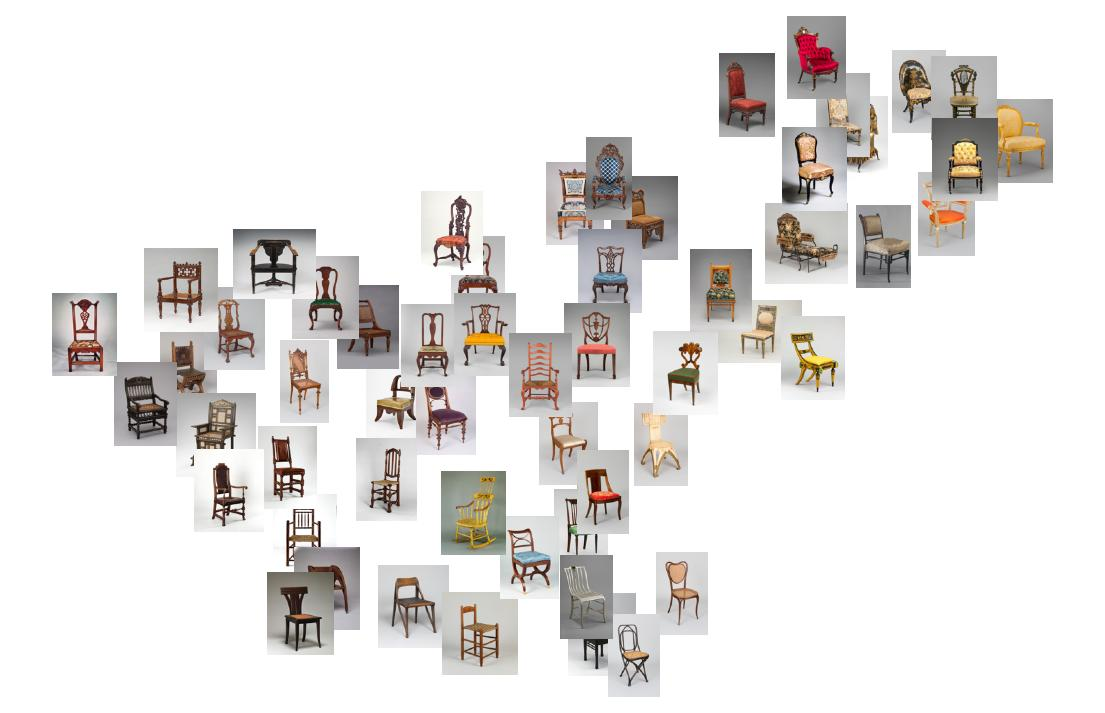

In [4]:
reducer = umap.UMAP(n_neighbors=min(15, len(train) - 1), min_dist=0.3, metric="cosine", random_state=0)
xy = reducer.fit_transform(E)

def thumb(ax, path, x, y, size=0.5):
    im = Image.open(path).convert("RGB")
    im.thumbnail((120, 120))
    ax.add_artist(AnnotationBbox(OffsetImage(np.asarray(im), zoom=size), (x, y), frameon=False))

fig, ax = plt.subplots(figsize=(14, 9))
for (x, y), p in zip(xy, train):
    thumb(ax, p, x, y)
pad = (xy.max(0) - xy.min(0)) * 0.08
ax.set_xlim(xy[:, 0].min() - pad[0], xy[:, 0].max() + pad[0])
ax.set_ylim(xy[:, 1].min() - pad[1], xy[:, 1].max() + pad[1])
ax.axis("off")
plt.savefig("map.jpg", dpi=120, bbox_inches="tight")
plt.show()

## 5. Search with words

It shows the four closest images for each phrase in WORDS. Pick your four phrases before you write your captions, or ask a teammate to pick them, so that your captions are not written to match them. You can change WORDS and run the cell again.

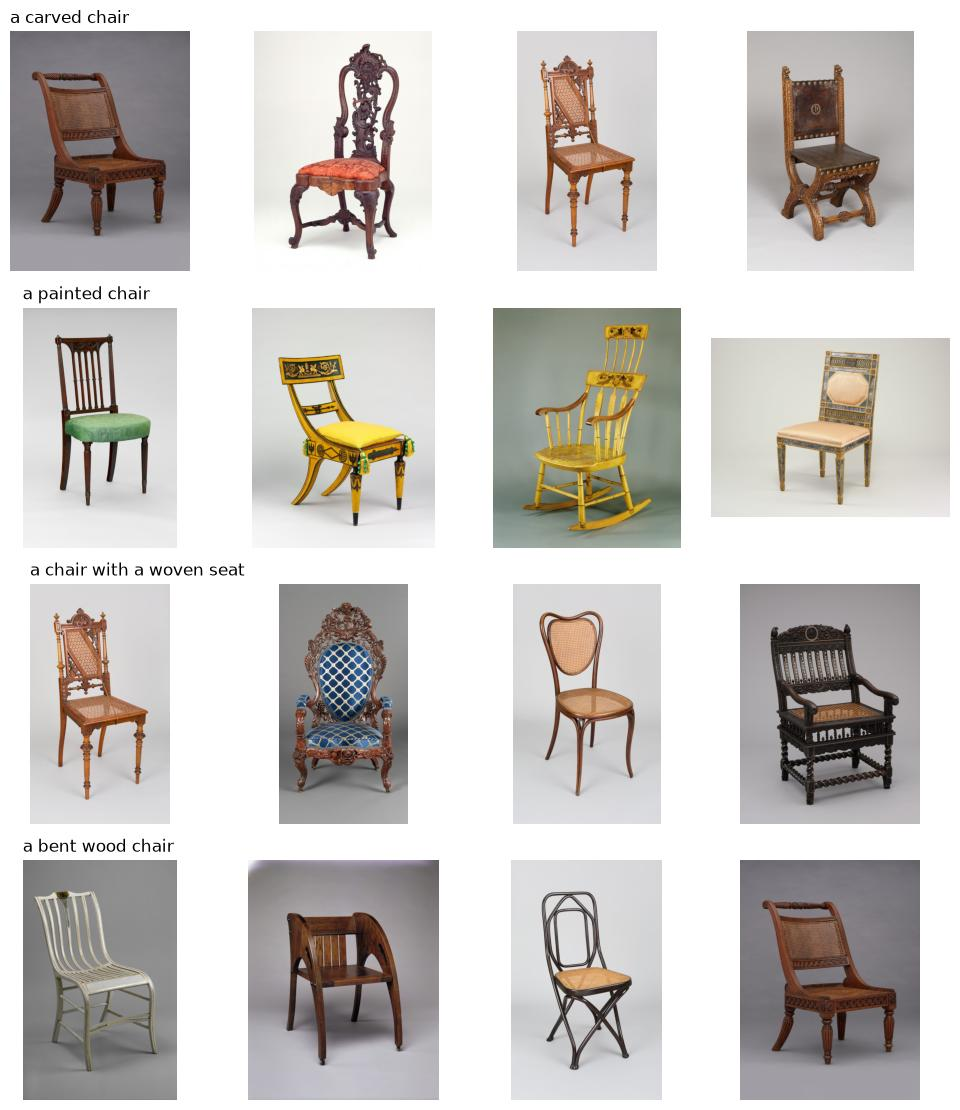

In [5]:
WORDS = ["carved", "painted", "a woven seat", "bent wood"]  # pick your four phrases before you write your captions

def phrase(w):
    return f"a {SUBJECT} with {w}" if w.startswith("a ") else f"a {w} {SUBJECT}"

with torch.no_grad():
    t = model.get_text_features(**proc(text=[f"a photo of {phrase(w)}" for w in WORDS], return_tensors="pt", padding=True).to(dev))
    if not torch.is_tensor(t):
        t = t.text_embeds if getattr(t, "text_embeds", None) is not None else t.pooler_output
        if t.shape[-1] != model.config.projection_dim:
            t = model.text_projection(t)
    T = torch.nn.functional.normalize(t, dim=-1).cpu().numpy()
S = T @ E.T
fig, axes = plt.subplots(len(WORDS), 4, figsize=(10, 2.8 * len(WORDS)), squeeze=False)
for i, w in enumerate(WORDS):
    for k, j in enumerate(np.argsort(-S[i])[:4]):
        axes[i, k].imshow(Image.open(train[j]).convert("RGB"))
        axes[i, k].axis("off")
    axes[i, 0].set_title(phrase(w), loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("search.jpg", dpi=110)
plt.show()

## 6. Compare two sets of captions

Download captions-template.csv from the Files panel on the left, write your own caption for each design in the caption column, and upload the file when the cell asks. You can also put it in your zip or Drive folder in section 2. A .csv file saved from Excel or Google Sheets works, and the cell lists any design that has no caption. The cell also writes captions automatically with BLIP, an image captioning model, which takes a few minutes. Then, for each phrase in WORDS, the cell finds the four designs whose captions are closest to the phrase, once with the automatic captions and once with yours. To compare captions and phrases, it uses all-MiniLM-L6-v2, a model that turns sentences into lists of numbers. Each caption is shown under its image, and the cell prints how many of the four are the same. With USE_EXAMPLE = True, the second set is the title and materials from each chair's museum record.

For the hand-in, download map.jpg and captions-compare.jpg from the Files panel on the left, and write a few sentences on which captions found the designs you meant, and what the other set missed. Add your answers to the Motivation and Composition questions of a datasheet for your set. [The datasheet for the museum chairs](https://github.com/chuanenlin/mlfordesign/blob/main/examples/museum-chairs/datasheet.md) is an example.

aic-100712.jpg
  automatic:      a close up of a chair with a floral seat cushion
  museum records: Side Chair, Walnut and 18th-century replacement upholstery
aic-102774.jpg
  automatic:      there is a chair with a foot rest and a foot rest on it
  museum records: Chair, Iron, walnut, cane, and upholstery
aic-105287.jpg
  automatic:      there is a wooden chair with a leather seat on a white background
  museum records: Side Chair, Bog oak and leather


a carved chair: 1 of the top 4 are the same
a painted chair: 1 of the top 4 are the same
a chair with a woven seat: 1 of the top 4 are the same
a bent wood chair: 1 of the top 4 are the same


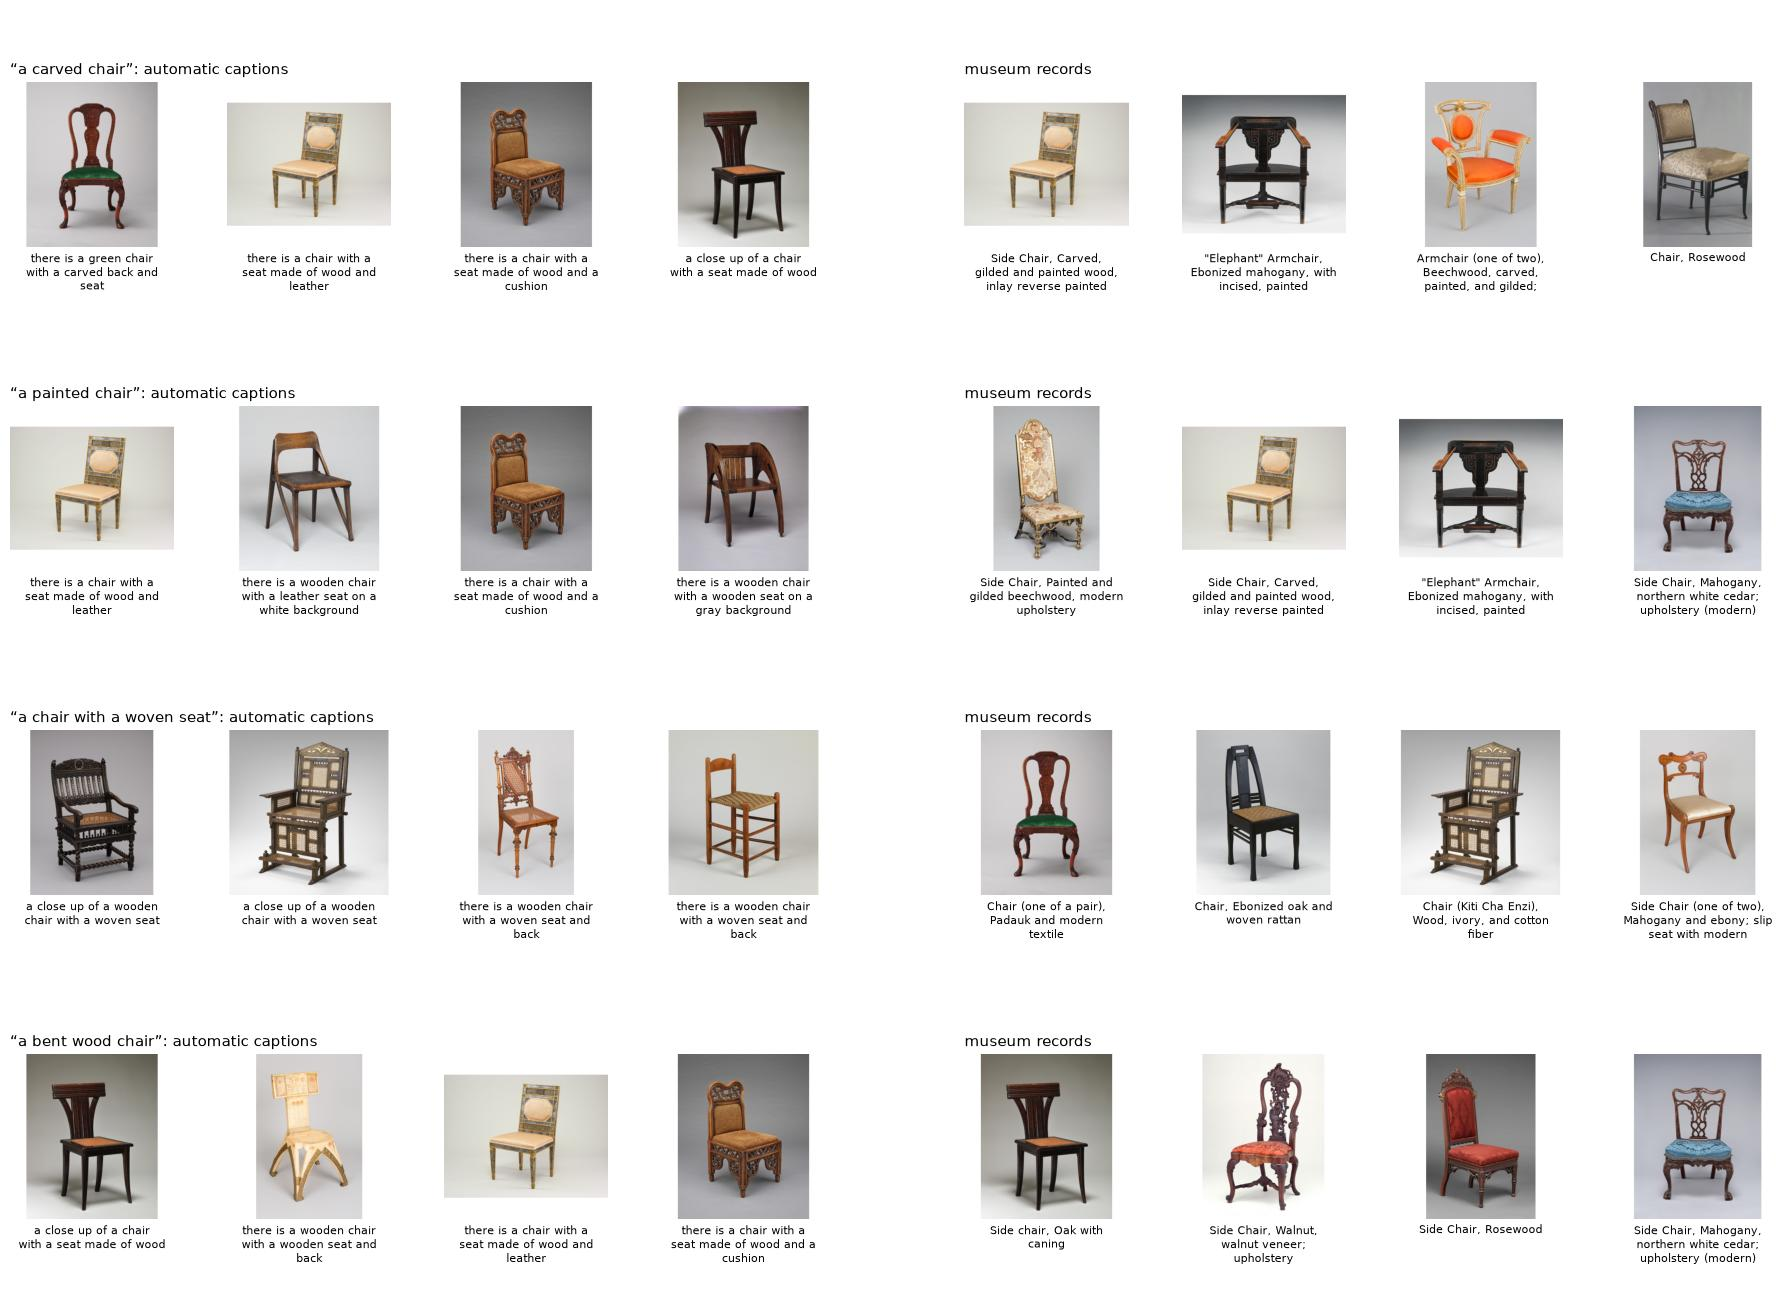

In [6]:
# Your captions: a .csv file with two columns, file and caption, one row for each image (start from captions-template.csv).
if USE_EXAMPLE:  # the second set for the example: each chair's title and materials from its museum record
    caption_text = requests.get(base + "captions-museum.csv", timeout=60).content.decode("utf-8-sig")
    yours_title = "museum records"
else:
    def with_captions(csvs):  # utf-8-sig also reads files saved from Excel
        texts = [d.decode("utf-8-sig") for d in csvs.values()]
        return next((t for t in texts if "caption" in t.split("\n")[0].lower()), None)
    caption_text = with_captions(uploaded_csvs)
    if caption_text is None:
        from google.colab import files
        print("Pick the .csv file with your captions:")
        caption_text = with_captions({n: d for n, d in files.upload().items() if n.lower().endswith(".csv")})
    if caption_text is None:
        raise ValueError("That file has no caption column. Start from captions-template.csv and run this cell again.")
    yours_title = "your captions"
rows = [{(k or "").strip().lower(): (v or "").strip() for k, v in r.items()} for r in csv.DictReader(io.StringIO(caption_text))]
if not rows or "file" not in rows[0] or "caption" not in rows[0]:
    raise ValueError("The captions file needs two columns named file and caption.")
by_name = {os.path.splitext(r["file"])[0]: r["caption"] for r in rows}
yours = [by_name.get(os.path.splitext(f)[0], "") for f in file_names]
missing = [f for f, y in zip(file_names, yours) if not y]
if missing:
    print(f"No caption for {len(missing)} of {len(file_names)} images:", ", ".join(missing))

from transformers import BlipForConditionalGeneration, BlipProcessor
bproc = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-large").to(dev).eval()
auto = []
with torch.no_grad():
    for p in train:
        out = blip.generate(**bproc(images=Image.open(p).convert("RGB"), return_tensors="pt").to(dev), max_new_tokens=30)
        auto.append(bproc.decode(out[0], skip_special_tokens=True))
for f, a, y in list(zip(file_names, auto, yours))[:3]:
    print(f"{f}\n  automatic:{' ' * (len(yours_title) - 9)} {a}\n  {yours_title}: {y}")

# A sentence model compares each phrase with each caption's words.
from sentence_transformers import SentenceTransformer
words_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")
A, Y, Q = (words_model.encode(x, normalize_embeddings=True) for x in (auto, yours, [phrase(w) for w in WORDS]))

def label(text, width=24):
    return "\n".join(textwrap.wrap(text, width)[:3])

def square(path, size=300):
    """The image on a white square, so that every image in the figure lines up."""
    im = Image.open(path).convert("RGB")
    im.thumbnail((size, size))
    sq = Image.new("RGB", (size, size), "white")
    sq.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return sq

fig, axes = plt.subplots(len(WORDS), 9, figsize=(18, 3.3 * len(WORDS)), squeeze=False,
                         gridspec_kw={"width_ratios": [1, 1, 1, 1, 0.2, 1, 1, 1, 1]})
for i, w in enumerate(WORDS):
    top_a, top_y = np.argsort(-(Q[i] @ A.T))[:4], np.argsort(-(Q[i] @ Y.T))[:4]
    for start, top, caps in [(0, top_a, auto), (5, top_y, yours)]:
        for k, j in enumerate(top):
            ax = axes[i, start + k]
            ax.imshow(square(train[j]))
            ax.set_xlabel(label(caps[j]), fontsize=8)
            ax.set_xticks([]); ax.set_yticks([])
            for side in ax.spines.values():
                side.set_visible(False)
    axes[i, 4].axis("off")
    axes[i, 0].set_title(f"“{phrase(w)}”: automatic captions", loc="left", fontsize=11)
    axes[i, 5].set_title(yours_title, loc="left", fontsize=11)
    print(f"{phrase(w)}: {len(set(top_a) & set(top_y))} of the top 4 are the same")
plt.tight_layout()
plt.savefig("captions-compare.jpg", dpi=100)
plt.show()